# Which Recipes Bring Traffic to the Homepage?

Tasty Bytes wants to know in advance which recipes will bring high traffic when they are featured on its homepage, and whether this can be predicted correctly at least 80% of the time. This notebook is my report for the DataCamp Data Scientist Professional Practical Exam (Recipe Site Traffic). It is written for the Head of Data Science, who wants to review the code and the reasoning behind each step.

**A note on AI use:** The code, the analysis, and the conclusions are my own work. I used AI (Claude) as a writing aid, to help me phrase my findings clearly and to tidy the notebook's formatting and comments.

## Context

Tasty Bytes is a recipe website that sells meal plans by monthly subscription. Each day, the Product Manager of Recipe Discovery chooses one favourite recipe from a selection and shows it on the homepage. When the recipe is popular, traffic to the rest of the website goes up by as much as 40%, and more traffic means more subscriptions. Today there is no way to know in advance whether a recipe will be popular.

The Product Manager gave us one row for each recipe in `data/recipe_site_traffic_2212.csv`, and warned that this is not all the information they have. The Head of Data Science asked me to check that the data really matches this description:

| Column | Description given in the brief |
| --- | --- |
| `recipe` | Numeric, unique identifier of the recipe |
| `calories` | Numeric, number of calories |
| `carbohydrate` | Numeric, amount of carbohydrates in grams |
| `sugar` | Numeric, amount of sugar in grams |
| `protein` | Numeric, amount of protein in grams |
| `category` | Character, one of ten groups: Lunch/Snacks, Beverages, Potato, Vegetable, Meat, Chicken, Pork, Dessert, Breakfast, One Dish Meal |
| `servings` | Numeric, number of servings for the recipe |
| `high_traffic` | Character, marked "High" if the traffic was high when the recipe was shown |

## Goal

The business goals come from the Product Manager's email:

1. **Predict which recipes will lead to high traffic.**
2. **Correctly predict high traffic recipes 80% of the time**, and keep the chance of showing an unpopular recipe low.
3. **Recommend what to do next**, whatever the results.

## Plan

1. Setup
2. Data validation: can the data be trusted?
3. Exploratory analysis: what makes a recipe popular?
4. Model development: a baseline model, the choice of columns, and a comparison model
5. Model evaluation: which model is better?
6. Business metric: can the 80% target be reached, and how reliably?
7. Summary and recommendations

## 1. Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, cross_val_predict, KFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn import metrics

RANDOM_STATE = 13  # makes the split, the folds and the forest reproducible
TEST_SIZE = 0.3  # 30% of the recipes go to the test set
CV_FOLDS = 5  # number of folds for cross-validation
TARGET_PRECISION = 0.8  # the product team's target: 80% of the chosen recipes bring high traffic
SAFETY_MARGIN = 0.05  # extra precision I ask for when choosing the cut (section 6.2)
NUTRIENTS = ["calories", "carbohydrate", "sugar", "protein"]  # the four nutrition columns

BLUE = "#2a78d6"  # main colour of the figures, also used for high traffic
ORANGE = "#eb6834"  # colour used to highlight, also used for low traffic
GREY = "#6b6b6b"  # colour of the reference lines

## 2. Data validation

The dataset has 947 rows and 8 columns. I checked every column against the description in the brief, cleaned what needed it, and removed no rows. Here is the result, and sections 2.1 to 2.5 show the checks behind it.

- **`recipe`**: 947 unique values from 1 to 947, no missing values, no duplicated rows. Matches the description, no cleaning needed.
- **`calories`**: numeric, no negative values, 52 missing values. I keep these rows and fill the missing values with the median (section 4.2).
- **`carbohydrate`**: numeric, no negative values, missing for the same 52 recipes. Same treatment.
- **`sugar`**: numeric, no negative values, missing for the same 52 recipes. Same treatment.
- **`protein`**: numeric, no negative values, missing for the same 52 recipes. Same treatment. Two recipes have a protein of 0, which is possible, so I keep them.
- **`category`**: 11 groups instead of the 10 in the brief, because of an extra "Chicken Breast" group. I merged its 98 recipes into "Chicken", which gives the expected 10 groups.
- **`servings`**: stored as text instead of numbers, because 3 recipes say "4 as a snack" or "6 as a snack". I kept the number and converted the column to integers. The values are now 1, 2, 4 and 6.
- **`high_traffic`**: contains only "High" and 373 empty cells. I replaced the empty cells with "Low", which is my reading of the brief, where only high traffic is marked.

One issue cannot be cleaned: the nutrition values are not fully reliable. For 21% of the recipes, sugar is above carbohydrate, which is not possible, and some values are hard to believe (section 2.2). I keep them as they are in the data, and in section 4.3 I decide not to use them in the model.

### 2.1 Load the data and check `recipe`

In [2]:
recipes = pd.read_csv("data/recipe_site_traffic_2212.csv")
recipes.head()

,recipe,calories,carbohydrate,sugar,protein,category,servings,high_traffic
0,1,NaN,NaN,NaN,NaN,Pork,6,High
1,2,35.48,38.56,0.66,0.92,Potato,4,High
2,3,914.28,42.68,3.09,2.88,Breakfast,1,NaN
3,4,97.03,30.56,38.63,0.02,Beverages,4,High
4,5,27.05,1.85,0.80,0.53,Beverages,4,NaN


In [3]:
recipes.info()

<class 'pandas.DataFrame'>
RangeIndex: 947 entries, 0 to 946
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   recipe        947 non-null    int64  
 1   calories      895 non-null    float64
 2   carbohydrate  895 non-null    float64
 3   sugar         895 non-null    float64
 4   protein       895 non-null    float64
 5   category      947 non-null    str    
 6   servings      947 non-null    str    
 7   high_traffic  574 non-null    str    
dtypes: float64(4), int64(1), str(3)
memory usage: 70.6 KB


In [4]:
print("Duplicated rows:", recipes.duplicated().sum())
print("Unique recipe ids:", recipes["recipe"].nunique(), "out of", len(recipes), "rows")
print("Lowest and highest id:", recipes["recipe"].min(), recipes["recipe"].max())

Duplicated rows: 0
Unique recipe ids: 947 out of 947 rows
Lowest and highest id: 1 947


`recipe` is a clean identifier: each of the 947 rows is a different recipe and no row is duplicated. 

`info()` also shows two differences with the brief: `servings` is text instead of a number, and `calories`, `carbohydrate`, `sugar`, `protein` and `high_traffic` have missing values.

### 2.2 Check the nutrition columns

In [5]:
recipes[NUTRIENTS].describe().round(2)  # summary statistics of the four nutrition columns

,calories,carbohydrate,sugar,protein
count,895.00,895.00,895.00,895.00
mean,435.94,35.07,9.05,24.15
std,453.02,43.95,14.68,36.37
min,0.14,0.03,0.01,0.00
25%,110.43,8.38,1.69,3.20
50%,288.55,21.48,4.55,10.80
75%,597.65,44.96,9.80,30.20
max,3633.16,530.42,148.75,363.36


In [6]:
print("Missing values per column:")
print(recipes[NUTRIENTS].isna().sum()) # Count of missing values in each nutrient column

print("\nRecipes with all four values missing:", recipes[NUTRIENTS].isna().all(axis=1).sum())
print("Recipes with at least one value missing:", recipes[NUTRIENTS].isna().any(axis=1).sum())
print("Negative values:", (recipes[NUTRIENTS] < 0).sum().sum())
print("Nutrients equal to 0:\n", (recipes[NUTRIENTS] == 0).sum()) # 

Missing values per column:
calories        52
carbohydrate    52
sugar           52
protein         52
dtype: int64

Recipes with all four values missing: 52
Recipes with at least one value missing: 52
Negative values: 0
Nutrients equal to 0:
 calories        0
carbohydrate    0
sugar           0
protein         2
dtype: int64


In [7]:
recipes.loc[recipes[NUTRIENTS].idxmax()] # idxmax gives the row of the highest value in each column, so this shows the most extreme recipe for each nutrient

,recipe,calories,carbohydrate,sugar,protein,category,servings,high_traffic
925,926,3633.16,29.07,0.35,2.32,Chicken,4,NaN
450,451,182.76,530.42,5.80,5.01,Potato,4,High
540,541,60.62,140.98,148.75,5.53,Dessert,1,NaN
681,682,339.38,5.75,10.19,363.36,Chicken Breast,6,High


In [8]:
recipes[recipes["calories"] < 1]  # recipes with less than one calorie

,recipe,calories,carbohydrate,sugar,protein,category,servings,high_traffic
228,229,0.14,18.12,11.15,87.34,Lunch/Snacks,2,High
276,277,0.76,1.90,3.76,0.05,Vegetable,2,High
500,501,0.30,5.19,0.96,1.51,Beverages,4,NaN
652,653,0.54,30.59,10.45,0.36,Beverages,6,High
654,655,0.59,18.82,58.00,16.44,Dessert,2,High
669,670,0.80,12.26,1.33,6.21,Chicken Breast,6,NaN
849,850,0.64,75.64,3.26,6.95,Breakfast,1,NaN


- The four columns are numeric and have no negative values.
- The 52 missing values are the same 52 recipes in all four columns. For these recipes, the nutrition information is missing as a block.
- Some values are very high, for example 3,633.16 calories for recipe 926, a Chicken recipe. The first table shows that the most extreme ones come from several categories.
  - The brief gives no limit, so I cannot really call them errors, and I keep them as is.
  - Some of them do look odd: recipe 451 has the most carbohydrate (530.42 grams) but only 182.76 calories.
- At the other end, 7 recipes have less than 1 calorie (second table) while containing several grams of food. 
  - For example, recipe 229 has 0.14 calories for 18.12 grams of carbohydrate and 87.34 grams of protein. 
  - Carbohydrate and protein always bring calories, so at least one of these values is wrong. 
  - The data does not say why: a typing error, a misplaced decimal point or a value entered in another unit are all possible.
- These odd values add to my doubts about the nutrition columns, which the next check makes clearer.

The brief warns that the data might not match the description, so I also check one rule that must hold for every recipe: sugar is a type of carbohydrate, so a recipe cannot contain more sugar than carbohydrate.

Sugar above carbohydrate: 185 of 895 recipes (21%)


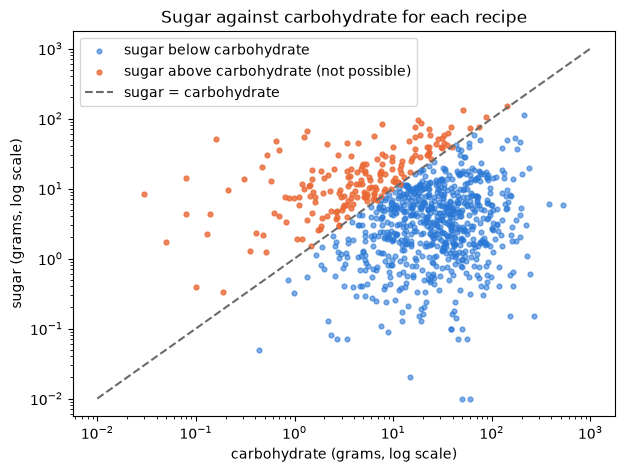

In [9]:
sugar_above_carbs = recipes["sugar"] > recipes["carbohydrate"]  # True when the rule is broken
recipes_with_values = recipes["calories"].notna().sum() # get the number of recipes with calorie values 
print("Sugar above carbohydrate:", sugar_above_carbs.sum(), "of", recipes_with_values, f"recipes ({sugar_above_carbs.sum() / recipes_with_values:.0%})") # the number of recipes where sugar is above carbohydrate

plt.figure(figsize=(7, 5))
plt.scatter(recipes.loc[~sugar_above_carbs, "carbohydrate"], recipes.loc[~sugar_above_carbs, "sugar"], # points where sugar is below carbohydrate
            s=12, alpha=0.6, color=BLUE, label="sugar below carbohydrate")
plt.scatter(recipes.loc[sugar_above_carbs, "carbohydrate"], recipes.loc[sugar_above_carbs, "sugar"], # points where sugar is above carbohydrate
            s=12, alpha=0.8, color=ORANGE, label="sugar above carbohydrate (not possible)")
plt.plot([0.01, 1000], [0.01, 1000], color=GREY, linestyle="--", label="sugar = carbohydrate")  # line to show the limit of the rule

plt.xscale("log")  # log axes, because most values are small and a few are very large
plt.yscale("log")
plt.title("Sugar against carbohydrate for each recipe")
plt.xlabel("carbohydrate (grams, log scale)")
plt.ylabel("sugar (grams, log scale)")
plt.legend(loc="upper left")
plt.show()

185 of the 895 recipes (21%) break the rule. 

This is not a handful of outliers, they form a whole cloud above the line, mostly among recipes with little carbohydrate. This could come from how the values were collected, but the data does not say. I cannot tell which value is wrong for each recipe, so I do not change them.

So I assume that the nutrition columns are not fully reliable: one recipe in five breaks this rule, and some extreme values are hard to believe. I keep them as they are for now. The exploration will show whether they still say something about traffic, and I decide in section 4.3 whether the model uses them.

### 2.3 Check and clean `category`

In [10]:
print(recipes["category"].value_counts()) # the number of recipes in each category

recipes["category"] = recipes["category"].replace({"Chicken Breast": "Chicken"})  # merge the extra group into Chicken

print("\nNumber of categories after cleaning:", recipes["category"].nunique())

category
Breakfast         106
Chicken Breast     98
Beverages          92
Lunch/Snacks       89
Potato             88
Pork               84
Vegetable          83
Dessert            83
Meat               79
Chicken            74
One Dish Meal      71
Name: count, dtype: int64

Number of categories after cleaning: 10


The brief describes 10 categories, or the data has 11 groups instead of 10, the extra one being "Chicken Breast". A chicken breast recipe is a chicken recipe and the brief has no separate group for it, so I merged the two.

### 2.4 Check and clean `servings`

The brief says this column is numeric, but `info()` showed text. I look at its values to see why.

In [11]:
print(recipes["servings"].value_counts())

recipes["servings"] = recipes["servings"].str.replace(" as a snack", "").astype(int)  # keep only the number in the strings and convert to int

print("\nAfter cleaning:")
print(recipes["servings"].value_counts().sort_index())

servings
4               389
6               197
2               183
1               175
4 as a snack      2
6 as a snack      1
Name: count, dtype: int64

After cleaning:
servings
1    175
2    183
4    391
6    198
Name: count, dtype: int64


Three recipes have "as a snack" after the number. I remove these words and keep the number, because the number of servings is what the column is meant to hold. The column now contains integers.

### 2.5 Check and clean `high_traffic`

This is the column I have to predict, so how I read it decides what the whole analysis means.

In [12]:
print(recipes["high_traffic"].value_counts())  # print the number of recipes in each traffic category
print("Missing values:", recipes["high_traffic"].isna().sum())  # counts the empty cells

recipes["high_traffic"] = recipes["high_traffic"].fillna("Low")  # an empty cell means the traffic was not high

print("\nAfter cleaning:")
print(recipes["high_traffic"].value_counts())

high_traffic
High    574
Name: count, dtype: int64
Missing values: 373

After cleaning:
high_traffic
High    574
Low     373
Name: count, dtype: int64


The only value is "High", and the other 373 cells are empty. The brief says that high traffic "is marked with High", so I read an empty cell as "not high" and write "Low". This is an assumption that the Product Manager should confirm.

Before deciding what to do with the 52 recipes that have no nutrition values, I check whether they behave like the others.

In [13]:
missing_nutrients = recipes["calories"].isna()  # find the recipes with missing values in the calories column

print("Missing values in calories column:", missing_nutrients.sum())

print("High traffic, recipes with missing values:", round((recipes.loc[missing_nutrients, "high_traffic"] == "High").mean(), 3)) # percentage of high traffic recipes with missing calories
print("High traffic, recipes with values:", round((recipes.loc[~missing_nutrients, "high_traffic"] == "High").mean(), 3)) # percentage of high traffic recipes with calories

Missing values in calories column: 52
High traffic, recipes with missing values: 0.75
High traffic, recipes with values: 0.598


75% of the recipes with missing nutrition values have high traffic, against 59.8% of the others. Removing them would take away a group of recipes that are more often popular, and their category, servings and traffic are known anyway. So I keep them.

The nutrition columns still show 895 values below on purpose: I fill the missing ones in section 4.2, after the train/test split, so that the test set has no influence on the values used to fill. The plots in section 3 simply skip the empty values.

In [14]:
recipes.info()

<class 'pandas.DataFrame'>
RangeIndex: 947 entries, 0 to 946
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   recipe        947 non-null    int64  
 1   calories      895 non-null    float64
 2   carbohydrate  895 non-null    float64
 3   sugar         895 non-null    float64
 4   protein       895 non-null    float64
 5   category      947 non-null    str    
 6   servings      947 non-null    int64  
 7   high_traffic  947 non-null    str    
dtypes: float64(4), int64(2), str(2)
memory usage: 70.0 KB


## 3. Exploratory analysis

The Product Manager's question is what makes a recipe popular. I start with how often it happens at all, then look at the nutrition values, the category, and whether nutrition still matters once the category is known.

### 3.1 How often does a featured recipe bring high traffic?

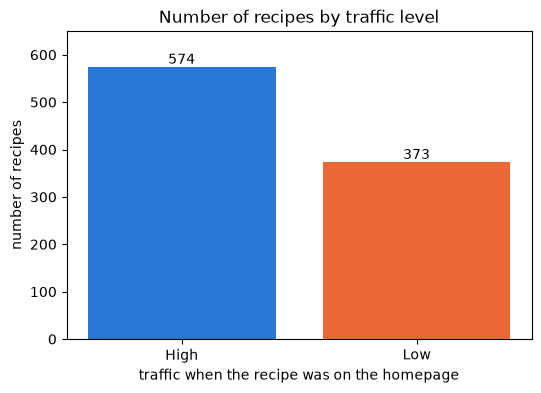

Share of high traffic recipes: 60.6%


In [15]:
traffic_counts = recipes["high_traffic"].value_counts() # the number of recipes in each traffic category
high_share = traffic_counts["High"] / len(recipes)  # the share of recipes with high traffic

plt.figure(figsize=(6, 4))
bars = plt.bar(traffic_counts.index, traffic_counts.values, color=[BLUE, ORANGE]) # create a bar chart with the counts of recipes in each traffic category

plt.bar_label(bars)  # write the count on top of each bar
plt.title("Number of recipes by traffic level")
plt.xlabel("traffic when the recipe was on the homepage")
plt.ylabel("number of recipes")
plt.ylim(0, 650)  # leave room for the count above the bar
plt.show()

print(f"Share of high traffic recipes: {high_share:.1%}")

574 of the 947 recipes brought high traffic (60.6%). 

All these recipes were featured on the homepage, so this is also my best estimate of how the current way of choosing performs as a baseline. About 6 good days out of 10 the recipe brings high traffic, where the target is 8. 

Any model has to beat this baseline to be useful. 

### 3.2 What do the nutrition values look like?

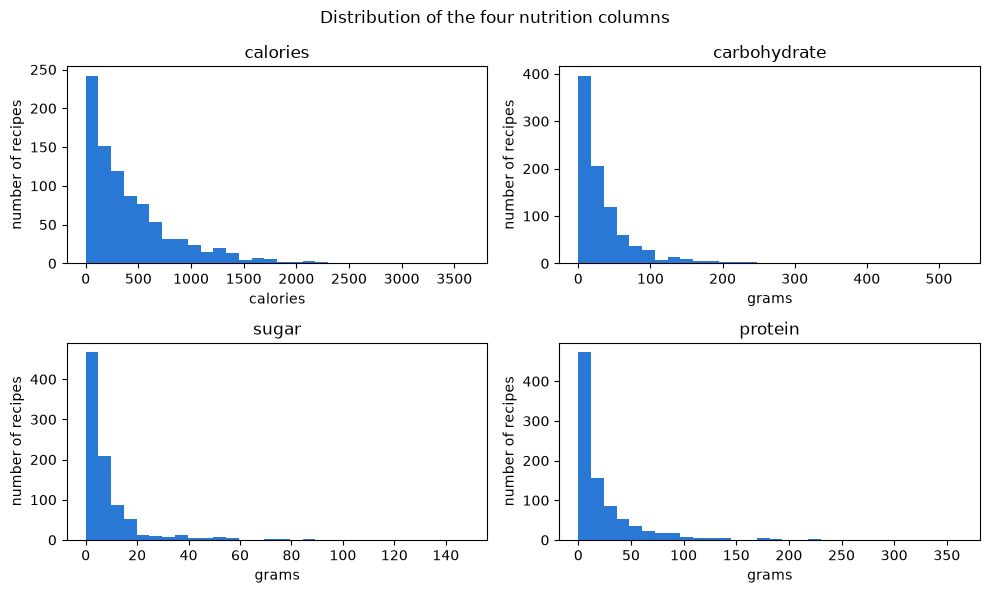

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
units = ["calories", "grams", "grams", "grams"]  # unit of each nutrition column

for ax, nutrient, unit in zip(axes.flatten(), NUTRIENTS, units): # iterate over the plots, nutrients, and units by position
# flatten() turns the grid of axes into a simple list of 4 plots, so that the loop can take them one by one.
    ax.hist(recipes[nutrient].dropna(), bins=30, color=BLUE)
    ax.set_title(nutrient)
    ax.set_xlabel(unit)
    ax.set_ylabel("number of recipes")

plt.suptitle("Distribution of the four nutrition columns")
plt.tight_layout()
plt.show()

What I notice:

- All four columns are strongly skewed: most recipes have small values and a few have very large ones.
- This is why I fill the missing values with the median and not the mean, because the mean is pulled up by the very large values.
- The columns are on very different scales (calories up to about 3,600, sugar up to about 150), so a logistic regression will need scaling.

### 3.3 Does the category matter?

My first guess is that visitors react to the type of dish more than to its nutrition, so I compare the share of high traffic between categories. The number of recipes is written next to each name, because a share based on few recipes is less reliable.

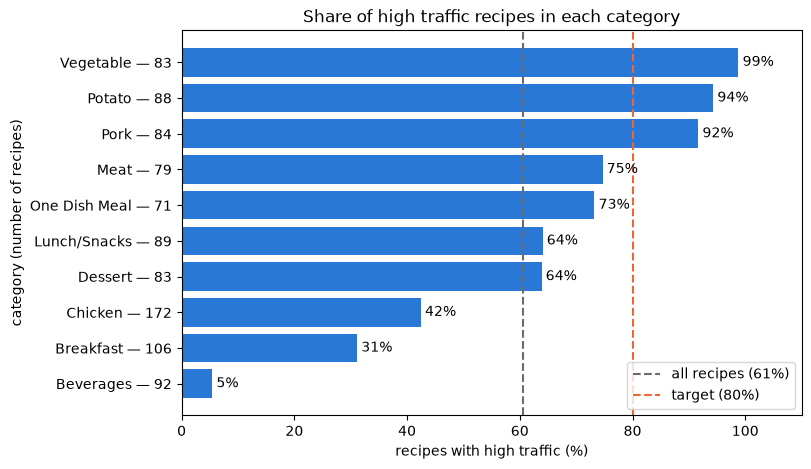

In [17]:
recipes["is_high"] = (recipes["high_traffic"] == "High").astype(int)  # 1 for high traffic, 0 for low traffic

category_stats = recipes.groupby("category")["is_high"].agg(["mean", "count"]).sort_values("mean")  # share of high traffic and number of recipes by category
category_labels = category_stats.index + " — " + category_stats["count"].astype(str)   # for example "Pork 84"

plt.figure(figsize=(8, 5))
bars = plt.barh(category_labels, category_stats["mean"] * 100, color=BLUE)

plt.axvline(high_share * 100, color=GREY, linestyle="--", label=f"all recipes ({high_share:.0%})") # draw a vertical line to show the share of high traffic recipes across all categories
plt.axvline(TARGET_PRECISION * 100, color=ORANGE, linestyle="--", label="target (80%)") # draw a vertical line to show the target precision of 80%

plt.bar_label(bars, fmt="%.0f%%", padding=3) # label for each bar with the percentage of high traffic recipes 
plt.title("Share of high traffic recipes in each category")
plt.xlabel("recipes with high traffic (%)")
plt.ylabel("category (number of recipes)")
plt.xlim(0, 110)
plt.legend(loc="lower right")
plt.show()

The gap is much larger than I expected:

- Almost every Vegetable recipe brought high traffic (99%), and almost no Beverages recipe did (5%).
- Only three categories are above the 80% target: Vegetable, Potato and Pork. With 83 to 88 recipes each, these are not small groups that could be high by chance.
- Chicken is the largest category after the merge (172 recipes) and only 42% of its recipes brought high traffic. Breakfast is at 31%.
- Meat, One Dish Meal, Lunch/Snacks and Dessert are in between, at 64% to 75%.

If the category alone explains this much, does nutrition add anything once the category is known?

### 3.4 Does nutrition matter once the category is known?

Over all recipes, popular recipes have slightly more calories, carbohydrate and protein:

In [18]:
recipes.groupby("high_traffic")[NUTRIENTS].median().round(1)  # median of each column for the two groups

,calories,carbohydrate,sugar,protein
high_traffic,,,,
High,305.1,23.2,4.2,12.0
Low,267.8,18.8,5.2,8.8


But a vegetable dish and a meat dish are very different in nutrition, so this small gap in nutrients could simply come from the category that are more popular. 

To separate the two, I compare popular and unpopular recipes inside each category. I keep the six categories with at least 10 recipes of each kind (High / Low), because the other four are almost all High or almost all Low. I show calories, the column with the largest gaps, and then the median difference for all four columns.

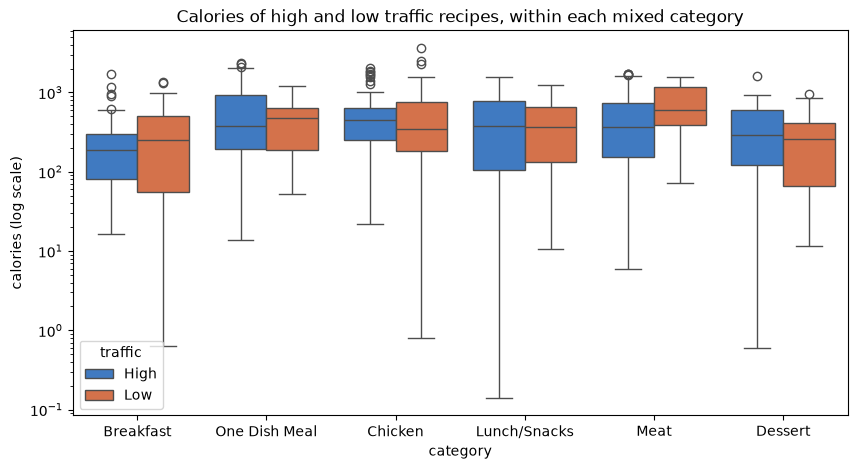

In [19]:
counts_by_category = recipes.groupby(["category", "high_traffic"]).size().unstack()  # recipes per category and traffic level
mixed_categories = counts_by_category[(counts_by_category["High"] >= 10) & (counts_by_category["Low"] >= 10)].index # categories with at least 10 recipes in each traffic level
mixed = recipes[recipes["category"].isin(mixed_categories)]  # recipes of the six mixed categories

plt.figure(figsize=(10, 5))
sns.boxplot(data=mixed, x="category", y="calories", hue="high_traffic", hue_order=["High", "Low"], palette=[BLUE, ORANGE])

plt.yscale("log")  # a log axis, because the values are very skewed
plt.title("Calories of high and low traffic recipes, within each mixed category")
plt.xlabel("category")
plt.ylabel("calories (log scale)")
plt.legend(title="traffic")
plt.show()

In [20]:
high_medians = mixed[mixed["high_traffic"] == "High"].groupby("category")[NUTRIENTS].median()
low_medians = mixed[mixed["high_traffic"] == "Low"].groupby("category")[NUTRIENTS].median()

print("Median of high traffic recipes - Median of low traffic recipes \n(positive: popular recipes have more nutrients)")
(high_medians - low_medians).round(1)

Median of high traffic recipes - Median of low traffic recipes 
(positive: popular recipes have more nutrients)


,calories,carbohydrate,sugar,protein
category,,,,
Breakfast,-60.2,-5.5,0.8,1.4
Chicken,103.3,-0.9,-1.0,5.1
Dessert,33.4,16.7,-6.5,0.4
Lunch/Snacks,7.1,-1.3,-0.7,-6.1
Meat,-235.8,5.8,2.4,1.7
One Dish Meal,-102.7,2.7,0.6,9.2


What I notice:

- Inside a category, the boxes of popular and unpopular recipes overlap heavily.
- The direction is not the same from one category to the next. Popular Chicken recipes have 103 more calories than unpopular ones (in median), while popular Meat recipes have 236 fewer. 
- Carbohydrate and sugar also go up in some categories and down in others.
- Protein is the most regular: a little higher for popular recipes in five of the six categories, by 9 grams at most, and lower in Lunch/Snacks.

So nutrition seems to describe the type of dish more than its popularity. Once the category is known, there is little left for nutrition to explain.

### 3.5 And the number of servings?

In [21]:
recipes.groupby("servings")["is_high"].agg(["mean", "count"]).round(3)  # share of high traffic and number of recipes for each number of servings

,mean,count
servings,,
1,0.589,175
2,0.574,183
4,0.606,391
6,0.652,198


The share of high traffic stays between 57% and 65% whatever the number of servings, close to the 61% of all recipes. Servings does not seem to matter.

**What the exploration suggests.** The category is the one strong signal, and servings looks weak. For the nutrition columns, two findings point the same way:

- they are not fully reliable: 21% of the recipes have more sugar than carbohydrate, and some (very high or very low) values are hard to believe (section 2.2);
- they do not separate popular and unpopular recipes within a category (section 3.4).

So I expect the model not to need the nutrition columns, and I test this in section 4.3 before deciding. I also expect a simple model to do as well as a flexible one, since there is little left to find beyond the category.

## 4. Model development

### 4.1 Type of problem and how I judge the models

The answer I need is a yes or no for each recipe: will it bring high traffic? 

This is a **binary classification** problem, where high traffic is the positive class (1) and low traffic is the negative class (0).

The main measure to use here is **precision**. 
- out of the recipes the model predicts as high traffic, what share really is bringin high traffic. 
- It corresponds to what the team asks for. A wrong "High" means showing an unpopular recipe and losing the traffic of that day. 
- A missed popular recipe costs much less: only one recipe is shown each day, and another one can take its place.

I also report three other measures for the full picture:

- **Recall**: out of the recipes that really bring high traffic, the share the model finds as high traffic.
- **Accuracy**: the share of all predictions that are right out of all predictions.
- **AUC**: if I take one high traffic recipe and one low traffic recipe, the AUC is the chance that the model gives the higher score to the high traffic one. 
  - 0.5 is a coin flip and 1 is perfect.

### 4.2 Prepare the data

- **Features:** the four nutrition columns, `servings` and `category`. 
  - I leave out `recipe`, because an identifier says nothing about popularity. 
  - I start with all the other columns, and I will test and decide in section 4.3 whether the nutrition columns are needed.
- **Category column:** a model needs numbers, so I turn it into one column per category with `get_dummies`. Beverages, the first one, becomes the reference.
- **Split:** I keep 30% of the recipes as a test set, with `stratify` so both training and test sets have the same share of high traffic.
- **Missing values:** I fill them with the median, inside a `Pipeline`. This way the median is computed on the training data only, at each step of the cross-validation as well.

In [22]:
# one column per category, the first category (Beverages) is the reference
category_dummies = pd.get_dummies(recipes["category"], prefix="category", drop_first=True, dtype=int)  # one 0/1 column per category where the row is 1 if the recipe belongs to that category, without Beverages used as the reference category

X = pd.concat([recipes[NUTRIENTS + ["servings"]], category_dummies], axis=1)  # get the numeric columns and the dummy columns side by side for the features
y = recipes["is_high"]  # the target: 1 for high traffic, 0 for low traffic

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y)

kf = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)  # the same 5 folds for every model

print("Train set:", X_train.shape)
print("Test set:", X_test.shape)
print("Share of high traffic in the train set:", round(y_train.mean(), 3))
print("Share of high traffic in the test set:", round(y_test.mean(), 3))
print("Missing nutrition rows in the train set:", X_train["calories"].isna().sum())
print("Missing nutrition rows in the test set:", X_test["calories"].isna().sum())

Train set: (662, 14)
Test set: (285, 14)
Share of high traffic in the train set: 0.606
Share of high traffic in the test set: 0.607
Missing nutrition rows in the train set: 34
Missing nutrition rows in the test set: 18


The train set has 662 recipes and the test set 285, with the same share of high traffic (about 61%). The 52 recipes with missing values are split between the two sets (34 and 18). 

The models, their settings and the cuts are all chosen on the train set. 
The test set is only used to check them.

### 4.3 Baseline model: logistic regression

I choose a **logistic regression** as the baseline, because it is simple, quick to fit and easy to explain: each column gets a coefficient that pushes the prediction up or down. It is sensitive to the scale of the data, which is why the `Pipeline` has a `StandardScaler`.

In [23]:
baseline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),  # fill the missing values with the median of the train set
    ("scaler", StandardScaler()),  # put all the columns on the same scale
    ("logreg", LogisticRegression(max_iter=1000)),  # more iterations so the model can finish learning
])

baseline.fit(X_train, y_train)

baseline_cv = cross_val_score(baseline, X_train, y_train, cv=kf, scoring="precision")  # one precision value per fold
print(f"Baseline, mean CV precision: {baseline_cv.mean():.3f}")

Baseline, mean CV precision: 0.790


The baseline reaches a mean cross-validation precision of 0.790. This is well above the 0.606 of choosing any featured recipe, but just under the 0.8 target.

**Does the model need the nutrition columns?** Sections 2.2 and 3.4 suggest that it does not. 

I test it directly : I fit the same logistic regression on different groups of columns and compare them with cross-validation on the train set.

In [24]:
category_columns = [column for column in X_train.columns if column.startswith("category_")] # get the list of the category columns, which start with "category_"

column_sets = {
    "All columns": list(X_train.columns), # all the columns, including nutrition, servings, and category
    "Without nutrition (category and servings)": category_columns + ["servings"], # all the columns except the nutrition columns
    "Without category (nutrition and servings)": NUTRIENTS + ["servings"], # all the columns except the category columns
}

subset_rows = []
for set_name, columns in column_sets.items(): 
    logreg = Pipeline([ # create a pipeline for the logistic regression
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("logreg", LogisticRegression(max_iter=1000)),
    ])

    subset_rows.append({
        "Columns used": set_name, # the name of the column set
        "Mean CV precision": cross_val_score(logreg, X_train[columns], y_train, cv=kf, scoring="precision").mean(), # the mean precision across the folds
        "Mean CV AUC": cross_val_score(logreg, X_train[columns], y_train, cv=kf, scoring="roc_auc").mean(), # the mean AUC across the folds
    })

pd.DataFrame(subset_rows).round(3)

,Columns used,Mean CV precision,Mean CV AUC
0,All columns,0.790,0.829
1,Without nutrition (category and servings),0.803,0.825
2,Without category (nutrition and servings),0.622,0.593


What I can notice in this case:

- Without the nutrition columns, the model does as well as with them: a slightly higher precision (0.803 against 0.790) and almost the same AUC (0.825 against 0.829).
- Without the category, the model is nearly useless: a precision of 0.622 is close to the 0.606 share of high traffic recipes, and an AUC of 0.593 is not far from a coin flip.

**Decision: I remove the nutrition columns from the model.** The model loses nothing without them, which agrees with section 3.4, where they did not separate popular recipes within a category. Their values are also not fully reliable (section 2.2), so a model that does not depend on them is safer. From here on, both models use `category` and `servings` only. These two columns have no missing values, so the pipeline no longer needs the imputer.

In [25]:
X = X.drop(columns=NUTRIENTS)  # from here on, the models use category and servings only
X_train = X_train.drop(columns=NUTRIENTS)
X_test = X_test.drop(columns=NUTRIENTS)

baseline = Pipeline([  # no imputer any more: category and servings have no missing values
    ("scaler", StandardScaler()),  # put all the columns on the same scale
    ("logreg", LogisticRegression(max_iter=1000)),
])
baseline.fit(X_train, y_train)

baseline_cv = cross_val_score(baseline, X_train, y_train, cv=kf, scoring="precision") # one precision value per fold

print("Columns used:", list(X_train.columns))
print("\nMissing values left in the train set:", X_train.isna().sum().sum())
print(f"\nBaseline without nutrition, mean CV precision: {baseline_cv.mean():.3f}")

Columns used: ['servings', 'category_Breakfast', 'category_Chicken', 'category_Dessert', 'category_Lunch/Snacks', 'category_Meat', 'category_One Dish Meal', 'category_Pork', 'category_Potato', 'category_Vegetable']

Missing values left in the train set: 0

Baseline without nutrition, mean CV precision: 0.803


### 4.4 Comparison model: random forest

I choose a **random forest** as the comparison model, because it works very differently: it combines many decision trees and can find combinations of columns that a logistic regression cannot see, for example a number of servings that only matters within one category. If such combinations exist, the forest should beat the baseline. It does not need scaling, and with no missing values left it does not need a `Pipeline` either.

A forest can easily overfit, so I tune how deep the trees can go and how small their last groups can be. `GridSearchCV` tries each combination with cross-validation and keeps the one with the best precision.

In [26]:
forest_model = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE)

param_grid = {
    "max_depth": [3, 5, 8, None],  # how many questions in a row each tree can ask
    "min_samples_leaf": [1, 5, 10, 20],  # the smallest group of recipes at the end of a branch
}

forest_grid = GridSearchCV(forest_model, param_grid=param_grid, cv=kf, scoring="precision") # search for the best hyperparameters using cross-validation and precision as the metric
forest_grid.fit(X_train, y_train)

forest = forest_grid.best_estimator_  # the best forest, already refitted on the whole train set

print("Best hyperparameters:", forest_grid.best_params_) # the best hyperparameters found for the best estimator
print(f"Random forest, mean CV precision: {forest_grid.best_score_:.3f}") # the mean precision across the folds

Best hyperparameters: {'max_depth': 8, 'min_samples_leaf': 20}
Random forest, mean CV precision: 0.803


The best forest has trees of depth 8 at most (`max_depth=8`) and at least 20 recipes in each final group (`min_samples_leaf=20`). Its mean cross-validation precision is 0.803, the same as the baseline.

## 5. Model evaluation

### 5.1 Compare the models with cross-validation

I compare the two models on the same 5 folds of the train set. This is where I choose the model, so that the test set stays independent.

In [27]:
models = {"Logistic regression": baseline, "Random forest": forest} # set a dictionary with the two models to compare
scorings = {"Precision": "precision", "Recall": "recall", "Accuracy": "accuracy", "AUC": "roc_auc"} # set a dictionary with the four metrics to compare

cv_table = pd.DataFrame(index=models.keys(), columns=scorings.keys(), dtype=float)  # empty table to fill using both dictionaries

for model_name, model in models.items():
    for score_name, scoring in scorings.items():
        cv_table.loc[model_name, score_name] = cross_val_score(model, X_train, y_train, cv=kf, scoring=scoring).mean()

cv_table.round(3)

,Precision,Recall,Accuracy,AUC
Logistic regression,0.803,0.803,0.763,0.825
Random forest,0.803,0.803,0.763,0.787


In [28]:
precision_folds = pd.DataFrame()  # one column per model, one row per fold

for model_name, model in models.items():
    precision_folds[model_name] = cross_val_score(model, X_train, y_train, cv=kf, scoring="precision")

print("Precision on each fold:")
print(precision_folds.round(3))
print("\nFolds where the two models have the same precision:",
      (precision_folds["Logistic regression"] == precision_folds["Random forest"]).sum(), "out of", CV_FOLDS)

chosen_model = "Logistic regression"  # the model I keep, see the text below

Precision on each fold:
   Logistic regression  Random forest
0                0.843          0.843
1                0.697          0.697
2                0.804          0.804
3                0.811          0.811
4                0.857          0.857

Folds where the two models have the same precision: 5 out of 5


- The two models have the same precision, recall and accuracy (0.803, 0.803 and 0.763), and the same precision on each of the 5 folds. At the default cut of 0.5 they predict High for the same recipes. With the category as the main signal, both predict High for the recipes of the categories where most recipes are popular.
- They differ only on AUC: 0.825 for the logistic regression against 0.787 for the forest. The AUC looks at the whole ranking of the probabilities, not only at the 0.5 cut, so the logistic regression ranks the recipes better. This matters in section 6, where I raise the cut.
- The folds vary a lot, from 0.697 to 0.857. I come back to this when choosing the cut (section 6.2).

As the exploration suggested, the flexible model finds nothing that the simple one misses. With the same precision, I keep the logistic regression, because it ranks the recipes better and it is simpler to explain.

### 5.2 Check the models on the test set

With the choice made, I evaluate both models on the test set, with the default cut: a recipe is predicted as high traffic if its probability is at least 0.5.

In [29]:
test_probs = {}  # probability of high traffic for each test recipe, per model
test_table = pd.DataFrame(index=models.keys(), columns=scorings.keys(), dtype=float)

for model_name, model in models.items():
    y_pred = model.predict(X_test)  # with the default cut of 0.5
    test_probs[model_name] = model.predict_proba(X_test)[:, 1]  # second column = probability of high traffic

    test_table.loc[model_name, "Precision"] = metrics.precision_score(y_test, y_pred)
    test_table.loc[model_name, "Recall"] = metrics.recall_score(y_test, y_pred)
    test_table.loc[model_name, "Accuracy"] = metrics.accuracy_score(y_test, y_pred)
    test_table.loc[model_name, "AUC"] = metrics.roc_auc_score(y_test, test_probs[model_name])

test_table.round(3)

,Precision,Recall,Accuracy,AUC
Logistic regression,0.8,0.809,0.761,0.826
Random forest,0.8,0.809,0.761,0.823


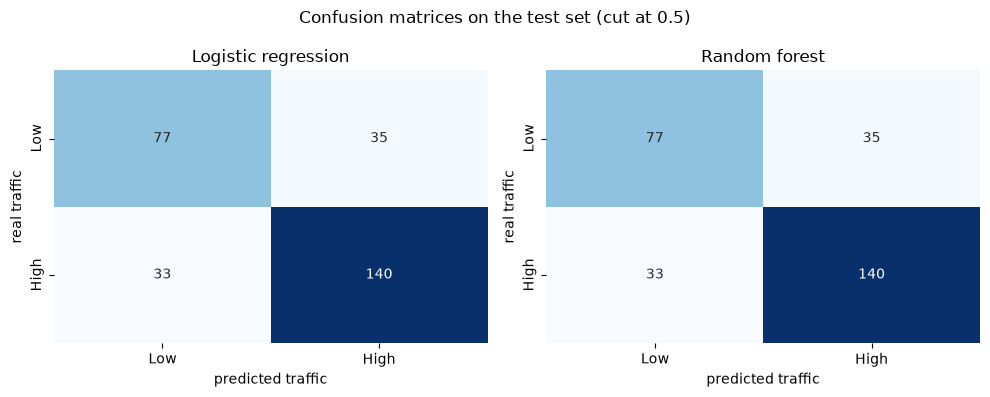

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, (model_name, model) in zip(axes, models.items()):
    confusion = metrics.confusion_matrix(y_test, model.predict(X_test))

    sns.heatmap(confusion, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax, xticklabels=["Low", "High"], yticklabels=["Low", "High"])  # annot writes the count in each cell
    ax.set_title(model_name)
    ax.set_xlabel("predicted traffic")
    ax.set_ylabel("real traffic")

plt.suptitle("Confusion matrices on the test set (cut at 0.5)")
plt.tight_layout()
plt.show()

- The two models make exactly the same predictions: precision 0.800, recall 0.809, accuracy 0.761, and the same confusion matrix. 140 of the 175 recipes predicted as High really are High, and 35 are not.
- The AUC is again a little higher for the logistic regression (0.826 against 0.823).
- The test precision (0.800) is close to the cross-validation score (0.803), so the models hold on new recipes.
- At the default cut, both models are exactly at the 80% target, with no room for error. Section 6 looks at how to get a safer result.

## 6. Business metric

### 6.1 The KPI and how to monitor it

**KPI: the share of recipes shown on the homepage that bring high traffic.** The target is 80%.

- **Why this KPI:**
  - The homepage shows one recipe a day, and the goal is that this recipe brings high traffic. The KPI counts exactly that, so it measures the business result and not only a model score. For a model, it is the precision on the High class.
  - It follows the cost of each error (section 4.1). A wrong "High" loses the traffic of that day, while a popular recipe that is not chosen costs almost nothing.
  - It needs only what the website already records (which recipe was shown and whether traffic was high). It is computed the same way for today's way of choosing, for the models and for the simple rule, so it makes a good benchmark for the comparison in section 6.4 to be fair.

- **How to monitor it:** 
  - At the end of each month, divide the number of homepage recipes with high traffic by the number of total recipes shown. 
  - One month is only about 30 recipes, and one recipe moves the KPI by more than 3 points, so I suggest looking after the next 3 months together and comparing with the 80% target.

- Starting value is 60.6% (section 3.1), corresponding to the current share of featured recipes with high traffic.

### 6.2 Raise the cut to reach the target

A model does not say "High" or "Low" directly. For each recipe, it gives a probability of high traffic, close to 1 for a Vegetable recipe, close to 0 for a Beverages recipe. The **cut** (also called the threshold) is the probability from which I predict "High". Until now I used the default cut of 0.5 meaning that a recipe with a probability of 0.5 or more is predicted "High".

If I raise the cut, for example to 0.75, only the recipes that the model is most sure about are kept. The choices are more reliable, but there are fewer recipes to choose from. Here this is a good trade: the homepage needs **one recipe a day**, not all the popular recipes. At the default cut, both models are just at 80%, with no room for error.

To choose the cut without touching the test set, I need a probability for each train recipe from a model that did not see it. This is what `cross_val_predict` does: it is like `cross_val_score`, but it returns the prediction for each recipe instead of a score for each fold.

In [31]:
cuts = [0.50, 0.55, 0.60, 0.65, 0.70, 0.75, 0.80, 0.85] # values of the cut to test
train_probs = {}  # probability of each train recipe, predicted by a model that did not see this recipe
cut_rows = []

for model_name, model in models.items():
    train_probs[model_name] = cross_val_predict(model, X_train, y_train, cv=kf, method="predict_proba")[:, 1]

    for cut in cuts: # iterate over the cut values to test
        chosen = train_probs[model_name] >= cut  # choose the recipes above the cut
        cut_rows.append({
            "Model": model_name,
            "Cut": cut,
            "Precision": y_train[chosen].mean(),
            "Share of recipes kept": chosen.mean(),
        })

cut_table = pd.DataFrame(cut_rows)
cut_table.round(3)

,Model,Cut,Precision,Share of recipes kept
0,Logistic regression,0.50,0.803,0.607
1,Logistic regression,0.55,0.803,0.607
2,Logistic regression,0.60,0.805,0.603
3,Logistic regression,0.65,0.815,0.530
4,Logistic regression,0.70,0.844,0.388
5,Logistic regression,0.75,0.924,0.299
6,Logistic regression,0.80,0.954,0.264
7,Logistic regression,0.85,0.954,0.264
8,Random forest,0.50,0.803,0.607
9,Random forest,0.55,0.804,0.585


Which cut should I take? The simplest answer is the lowest cut that reaches 80%, because it keeps the most recipes. But in section 5.1 the precision of the logistic regression moved from 0.697 to 0.857 between folds, so a cut that only just reaches 80% here could easily fall below it on new recipes. **I take the lowest cut that reaches 85%**, a safety margin of 5 points. Section 6.5 checks that the result holds on other splits.

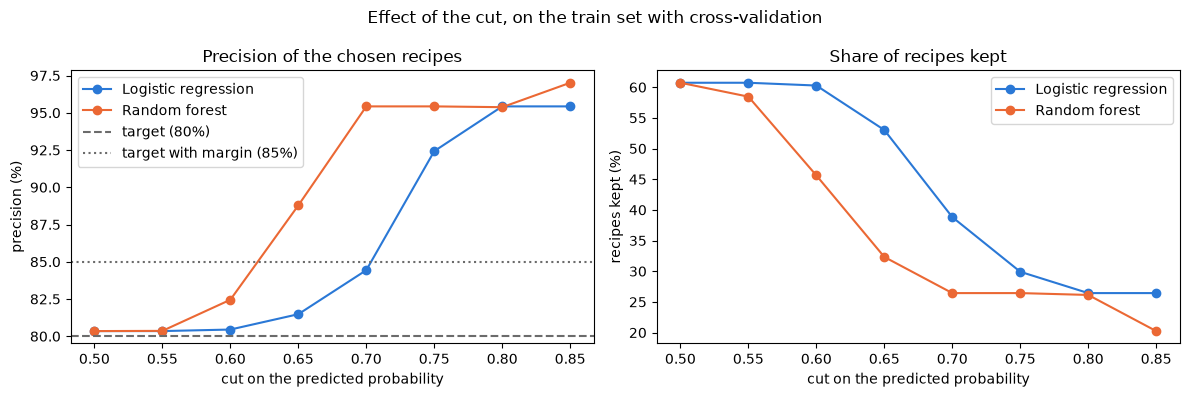

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)

for model_name, color in zip(models.keys(), [BLUE, ORANGE]): # iterate over the models
    model_rows = cut_table[cut_table["Model"] == model_name] # get the rows corresponding to the model
    axes[0].plot(model_rows["Cut"], model_rows["Precision"] * 100, color=color, marker="o", label=model_name) # plot the precision of the chosen recipes for each cut
    axes[1].plot(model_rows["Cut"], model_rows["Share of recipes kept"] * 100, color=color, marker="o", label=model_name) # plot the share of recipes kept for each cut

axes[0].axhline(TARGET_PRECISION * 100, color=GREY, linestyle="--", label="target (80%)") # draw a horizontal line to show the target precision of 80%
axes[0].axhline((TARGET_PRECISION + SAFETY_MARGIN) * 100, color=GREY, linestyle=":", label="target with margin (85%)") # draw a horizontal line to show the target precision of 85% (80% + 5% margin)
axes[0].set_title("Precision of the chosen recipes")
axes[0].set_xlabel("cut on the predicted probability")
axes[0].set_ylabel("precision (%)")
axes[0].legend()

axes[1].set_title("Share of recipes kept")
axes[1].set_xlabel("cut on the predicted probability")
axes[1].set_ylabel("recipes kept (%)")
axes[1].legend()

plt.suptitle("Effect of the cut, on the train set with cross-validation")
plt.tight_layout()
plt.show()

In [33]:
chosen_cuts = {}

for model_name in models.keys():
    model_rows = cut_table[cut_table["Model"] == model_name] # get the rows corresponding to the model
    above_target = model_rows[model_rows["Precision"] >= TARGET_PRECISION + SAFETY_MARGIN]  # select the precision values that are above the target with margin
    chosen_cuts[model_name] = above_target["Cut"].min() # the lowest cut that reaches 85% keeps the most recipes

    best_row = above_target[above_target["Cut"] == chosen_cuts[model_name]].iloc[0] # locate the row information for the chosen cut 
    print(f"{model_name}: cut {best_row['Cut']:.2f}, with a precision of {best_row['Precision']:.3f}, that keeps {best_row['Share of recipes kept']:.1%} of the recipes")

Logistic regression: cut 0.75, with a precision of 0.924, that keeps 29.9% of the recipes
Random forest: cut 0.65, with a precision of 0.888, that keeps 32.3% of the recipes


Each model gets its own cut, chosen by the same rule. Close to a third of the recipes is still a wide choice for one recipe a day.

### 6.3 A simple rule as a point of comparison

Since the model seems to rely mostly on the categories, I want to know how far a rule without any model can go: only pick recipes from the categories above the 80% target in the train set. If it does as well, the team does not need a model.

In [34]:
train_recipes = recipes.loc[X_train.index]  # the recipes of the train set, with their original columns 

train_category_share = train_recipes.groupby("category")["is_high"].mean().sort_values(ascending=False)
top_categories = list(train_category_share[train_category_share >= TARGET_PRECISION].index)  # categories above the target

print(train_category_share.round(3))
print("\nCategories in the simple rule:", top_categories)

in_rule_train = train_recipes["category"].isin(top_categories)
print("Precision of the rule on the train set:", round(train_recipes.loc[in_rule_train, "is_high"].mean(), 3))
print("Recipes in these categories, in the whole dataset:", recipes["category"].isin(top_categories).sum())

category
Vegetable        0.984
Potato           0.966
Pork             0.907
Meat             0.731
One Dish Meal    0.722
Lunch/Snacks     0.661
Dessert          0.644
Chicken          0.433
Breakfast        0.333
Beverages        0.029
Name: is_high, dtype: float64

Categories in the simple rule: ['Vegetable', 'Potato', 'Pork']
Precision of the rule on the train set: 0.954
Recipes in these categories, in the whole dataset: 255


The rule keeps the same three categories as the exploration: Vegetable, Potato and Pork. On the train set, 95.4% of their recipes bring high traffic, and there are 255 such recipes in the whole dataset.

### 6.4 The KPI on the test set

I now compare all the approaches with the KPI, on the same 285 test recipes. "Today" means taking any featured recipe, as in the data.

In [35]:
test_recipes = recipes.loc[X_test.index]  # the recipes of the test set, with their original columns

# the recipes each approach chooses in the test set
approaches = {
    "Today: any featured recipe": np.ones(len(y_test), dtype=bool), # np.ones creates an array of True values, meaning all recipes are chosen
    "Logistic regression, cut 0.5": test_probs["Logistic regression"] >= 0.5, # True for the recipes above the cut
    "Random forest, cut 0.5": test_probs["Random forest"] >= 0.5,
    f"Logistic regression, cut {chosen_cuts['Logistic regression']:.2f}": test_probs["Logistic regression"] >= chosen_cuts["Logistic regression"], # True for the recipes above the chosen cut
    f"Random forest, cut {chosen_cuts['Random forest']:.2f}": test_probs["Random forest"] >= chosen_cuts["Random forest"], 
    "Simple rule: top categories": test_recipes["category"].isin(top_categories).values, # True for the recipes in the top categories
}

kpi_rows = []
for approach_name, chosen in approaches.items():
    kpi_rows.append({
        "Approach": approach_name,
        "KPI (precision)": y_test[chosen].mean(),
        "Recipes chosen": chosen.sum(),
        "Share of recipes kept": chosen.mean(),
        "Recall": y_test[chosen].sum() / y_test.sum(), 
    })

kpi_table = pd.DataFrame(kpi_rows).set_index("Approach")
kpi_table.round(3)

,KPI (precision),Recipes chosen,Share of recipes kept,Recall
Approach,,,,
Today: any featured recipe,0.607,285,1.000,1.000
"Logistic regression, cut 0.5",0.800,175,0.614,0.809
"Random forest, cut 0.5",0.800,175,0.614,0.809
"Logistic regression, cut 0.75",0.938,80,0.281,0.434
"Random forest, cut 0.65",0.899,109,0.382,0.566
Simple rule: top categories,0.938,80,0.281,0.434


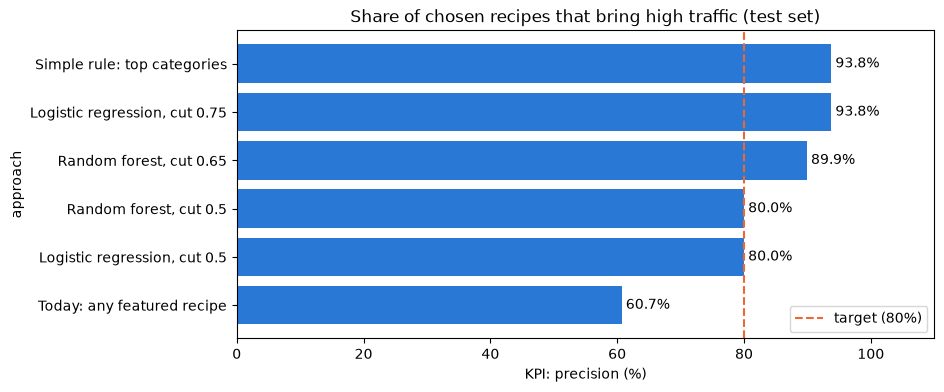

In [36]:
kpi_plot_table = kpi_table.sort_values("KPI (precision)")

plt.figure(figsize=(9, 4))
bars = plt.barh(kpi_plot_table.index, kpi_plot_table["KPI (precision)"] * 100, color=BLUE) 

plt.bar_label(bars, fmt="%.1f%%", padding=3)  # write the KPI at the end of each bar 
plt.axvline(TARGET_PRECISION * 100, color=ORANGE, linestyle="--", label="target (80%)") 
plt.title("Share of chosen recipes that bring high traffic (test set)")
plt.xlabel("KPI: precision (%)")
plt.ylabel("approach")
plt.xlim(0, 110)
plt.legend(loc="lower right")
plt.show()

- Today's way of choosing is at 60.7% on the test set, far from the 80% target.
- At the default cut, both models are exactly at the target (80.0%), with 175 recipes chosen.
- With the cuts chosen earlier, both clearly cross the target, 93.8% for the logistic regression and 89.9% for the forest. The forest keeps more recipes (109 against 80), but with a lower KPI.
- The price to pay is recall, at 0.75, the logistic regression finds 43.4% of the popular recipes. This matters less when the homepage just needs one working recipe a day.
- The logistic regression and the simple rule have the same result: 93.8%, with 80 recipes each.
  - All 80 recipes chosen by the logistic regression come from Vegetable, Potato and Pork. We can confidently infer that the model chooses the same recipes as the rule. Considering the number of columns this is expected, the model only knows the category and the number of servings, and servings matters little.

### 6.5 Does the result hold on other train / test splits?

All the test numbers above come from one split of 285 recipes, and another split would give other numbers. To see how much this matters, I repeat the process at once on 20 different seed splits. Each time, the train part and the test part are new: I fit the logistic regression again on the train part and measure the KPI on the test part. I keep the decisions already made, which are the cut chosen in section 6.2 and the three categories of the simple rule from section 6.3. I add the default cut of 0.5, to show what raising the cut brings. These decisions were taken on one train set, so the 20 splits show how much the result depends on the test set, not whether the choice itself is stable. 

Today's value is left out because it does not move: `stratify` keeps 60.7% of high traffic recipes in every test set. I leave out the random forest, because its tuning would take much longer to repeat and the logistic regression is the model I keep.

In [37]:
split_rows = []
chosen_cut = chosen_cuts["Logistic regression"]  # the cut chosen in section 6.2

for seed in range(20):  # 20 different splits of the data
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=TEST_SIZE, random_state=seed, stratify=y)
    split_model = Pipeline([
        ("scaler", StandardScaler()),
        ("logreg", LogisticRegression(max_iter=1000)),
    ])
    
    split_model.fit(X_tr, y_tr)  # fit again on the new train part
    test_prob = split_model.predict_proba(X_te)[:, 1]  # probability of high traffic for the new test part
    in_rule = recipes.loc[X_te.index, "category"].isin(top_categories).values  # the same three categories as in section 6.3

    split_rows.append({
        "Logistic regression, cut 0.5": y_te[test_prob >= 0.5].mean(), # precision of the recipes above the base cut of 0.5
        f"Logistic regression, cut {chosen_cut:.2f}": y_te[test_prob >= chosen_cut].mean(), # precision of the recipes above the chosen cut
        "Simple rule": y_te[in_rule].mean(), # precision of the recipes in the top categories rule
    })

split_table = pd.DataFrame(split_rows)

split_summary = pd.DataFrame({
    "Mean KPI": split_table.mean(),
    "Lowest KPI": split_table.min(),
    "Splits reaching 80%": (split_table >= TARGET_PRECISION).sum(),
})
split_summary.round(3)

,Mean KPI,Lowest KPI,Splits reaching 80%
"Logistic regression, cut 0.5",0.807,0.755,14
"Logistic regression, cut 0.75",0.912,0.863,20
Simple rule,0.948,0.918,20


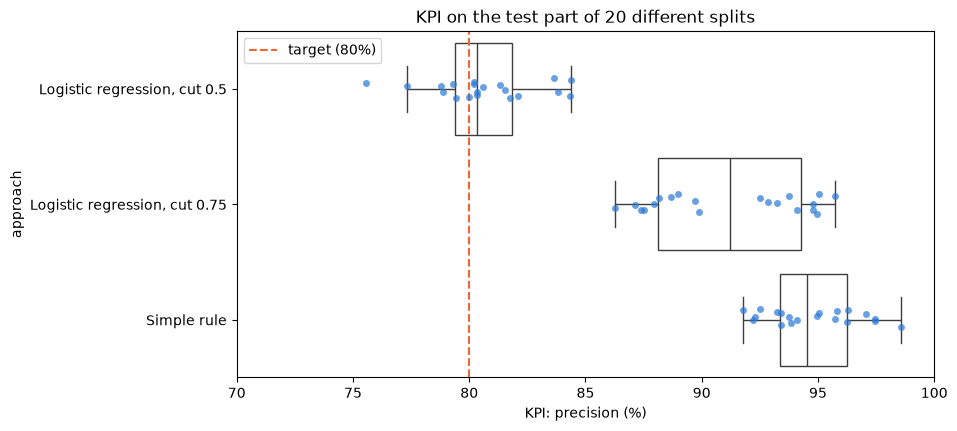

In [38]:
plt.figure(figsize=(9, 4.5))
sns.boxplot(data=split_table * 100, orient="h", color="white", showfliers=False)  # boxplot of the KPI across the 20 splits
sns.stripplot(data=split_table * 100, orient="h", color=BLUE, size=5, alpha=0.7)  # one point per split seed

plt.axvline(TARGET_PRECISION * 100, color=ORANGE, linestyle="--", label="target (80%)") # draw a vertical line to show the target precision of 80%
plt.title("KPI on the test part of 20 different splits")
plt.xlabel("KPI: precision (%)")
plt.ylabel("approach")
plt.xlim(70, 100)
plt.legend(loc="upper left")
plt.show()

Results to conclude here is that :

- **The default cut is not safe:** At a cut of 0.5, the KPI is 80.7% on average, but above the target on only 14 of the 20 splits, and it falls to 75.5% on the worst one.
- **The chosen cut is safe:** At 0.75, all 20 splits are above the target, with a mean of 91.2% and a lowest value of 86.3%.
- **The simple rule is above the target on all 20 splits**, with a mean of 94.8% and never below 91.8%.

So the 93.8% of section 6.4 is close to the typical result of the model (91.2%) on the different splits, and the conclusion holds. 
- With the raised cut, the logistic regression reaches the 80% target on new test sets, not only on average. 
- The rule stays a little ahead with the current data, so it suggests that an ML model do not bring additional value

## 7. Summary and recommendations

The table brings together the results on the test set.

In [39]:
summary = kpi_table[["KPI (precision)", "Recipes chosen", "Recall"]].copy()
summary["Reaches 80%"] = summary["KPI (precision)"] >= TARGET_PRECISION  # compare the KPI with the target
summary.round(3)

,KPI (precision),Recipes chosen,Recall,Reaches 80%
Approach,,,,
Today: any featured recipe,0.607,285,1.000,False
"Logistic regression, cut 0.5",0.800,175,0.809,True
"Random forest, cut 0.5",0.800,175,0.809,True
"Logistic regression, cut 0.75",0.938,80,0.434,True
"Random forest, cut 0.65",0.899,109,0.566,True
Simple rule: top categories,0.938,80,0.434,True


**What the results show**

- **Can we predict which recipes bring high traffic?** 
  - Yes, from their category. Vegetable, Potato and Pork recipes almost always bring high traffic, and Beverages, Breakfast and Chicken rarely have a bigger success. 
  - Servings feature adds almost nothing. 
  - The nutrition columns add nothing to the model and part of their values are not reliable, so I removed them.

- **Can we be right 80% of the time?** 
  - Yes, if we accept that the list of recipes to choose from will be much more limited than before
  - The logistic regression with a cut of 0.75 reaches 93.8% on the test set, against 60.7% for today's way of choosing. 
  - Over 20 different splits, it reached the target every time, with a mean of 91.2%. 
  - At the default cut of 0.5, it was below the target on 6 of the 20 splits.

- **Which model to choose?** 
  - The logistic regression. Both selected models have the same cross-validation precision (0.803), but the logistic regression ranks the recipes better (AUC 0.825 against 0.787), reaches a higher KPI with its chosen cut (93.8% against 89.9%), and is simpler to understand.

- **Choose the model or rule?** 
  - At this level of reliability, the model chooses the same 80 test recipes as the simple rule, all from Vegetable, Potato and Pork. 
  - With the current data, the rule is more straightforward, the model adds nothing to the rule. 
  - The only added value of the model is that the same process can take in new information when it becomes available

- **In practical terms:** 
  - Going from about 61% to about 90% means roughly 30 more high traffic days out of 100. I cannot convert this information into visitors or subscriptions, because the data has no traffic numbers.

**Recommendations**

1. **Start now with the categories.** 
   - We know now that featuring Vegetable, Potato and Pork recipes in priority, and avoid Beverages, Breakfast and Chicken, brings higher traffic. 
   - This needs no model, because it reached 93.8% on the test set and stayed above 80% on all 20 splits. 
  
2. **Collect better data:** 
   - For example, some metrics like the time to make and the cost per serving, the ingredients, the date each recipe was shown and the real traffic numbers. 
   - The nutrition values should also be checked and reworked at the source. Once they are reliable, they are worth testing again in the model.
   - Add the number of new subscriptions and cancellations, so that a future model can link the recipe of the day to subscriptions, not only to traffic.



3. **Keep the logistic regression ready, and use it once new data arrives.** 
   - Today it chooses the same recipes as the rule, so it adds nothing on its own. 
   - Once new columns are added, retrain it with the same process and the same KPI, and let it replace the rule only if it does better.
  
4. **Test before deciding with an A/B test** 
   - For a few weeks, split the visitors at random on the same day
     - Group A sees the recipe chosen the old way 
     - Group B sees the recipe chosen the new way
     - Compare how many visitors in each group continue to other pages and how many subscribe.
   - This would be the best way to know if the change itself brings more traffic and subscriptions, and whether showing mainly three categories of recipe tires visitors, which this data cannot tell.
   - This strategy may cost some traffic but can help refine the strategy

5. **Monitor the KPI over time** 
   - For example, if it does not meet the requirements over 3 months, the team should review the categories and the data before retraining the model, trying to figure out more accurate results.


**Limits**

- The data shows that some categories are linked to high traffic, not that they cause it. Traffic also depends on things outside the recipe, such as the season, the day of the week or a holiday, and the way recipes were chosen could also play a part. 
  
- The KPI counts days with high traffic which does not mean more subscription every time. 
  
- The data only covers featured recipes chosen by the Product Manager, so the results may not hold for recipes that were never shown that could bring high traffic as well
  
- High traffic" is not defined, I do not know the threshold behind it, and I assumed that empty cells mean low traffic.
  
- The KPI of 93.8% rests on 80 test recipes which is a small number, and the 20 splits show it could be as low as 86.3% on another sample showing high variations.
  
- The nutrition columns are left out because they add nothing to the model and part of their values are not reliable, so I removed them. The errors may hide some useful information, which this data cannot show.
  
- I did not test other types of model that could perform better.